# TASK 4: Visualizing Fire Scars through False Color
Github Repository Link: https://github.com/nberry18/eds220-hwk4.git

## About
In February 2021, a severe winter storm swept across the U.S. central plains, setting national records for low temperatures. Texas was especially affected, with widespread electricity and water outages. This event ranks among the most severe winter weather incidents in history, resulting in loss of life and long-term economic consequences. In the aftermath, political debate and blame can obscure the facts.

## Readings
NASA EARTH OBSERVATORY
WHAT ARE THE BANDS DESIGNATION
COmmon LANDSAT BAND COMBOS
About the Data
In this task you will see two datasets:

First dataset: Landsat Collection 2 Level-2 atmospherically:

Collection of bands (red,green,blue,near-infrared and shortwave infared)
landsat8-2025-02-23-palisades-eaton.nc
Second dataset:Fire perimeters for the Eaton and Palisades fires:

More than one File
California_Fire_Perimeters_2017


# 1. Import Libraries 

In [2]:
#import packages
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr
import rioxarray

# 2. Import Data Fire Perimeter Data

In [3]:
eaton = gpd.read_file(os.path.join(
                      'data',
                      'Eaton_Perimeter_20250121',
                      'Eaton_Perimeter_20250121.shp'))

palisades = gpd.read_file(os.path.join(
                         'data',
                         'Palisades_Perimieter_20250121',
                         'Palisades_Perimieter_20250121.shp'))

# 3. Eaton and Palisades fire perimeter data exploration

In [4]:
eaton.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},2025-01-08T00:00:00Z,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((-118.10093 34.16680, -118.1008..."


In [5]:
eaton.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [6]:
eaton.info

<bound method DataFrame.info of    OBJECTID  YEAR_ STATE AGENCY UNIT_ID FIRE_NAME            type   INC_NUM  \
0         1   2025    CA    CDF     LAC     EATON  Heat Perimeter  00009087   

                                  IRWINID            ALARM_DATE  ...  \
0  {72660ADC-B5EF-4D96-A33F-B4EA3740A4E3}  2025-01-08T00:00:00Z  ...   

  GIS_ACRES  COMMENTS  COMPLEX_NA  COMPLEX_ID  FIRE_NUM  \
0  14056.26      None        None        None      None   

                               GlobalID    DECADES Shape__Are Shape__Len  \
0  000a99c2-0fef-4960-a3c4-f2342a0cd291  2020-2025   0.005564   0.859026   

                                            geometry  
0  MULTIPOLYGON (((-118.10093 34.16680, -118.1008...  

[1 rows x 24 columns]>

In [8]:
palisades.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07T00:00:00Z,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((-118.51974 34.02996, -118.5198..."


In [9]:
palisades.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [10]:
palisades.info

<bound method DataFrame.info of    OBJECTID  YEAR_ STATE AGENCY UNIT_ID  FIRE_NAME            type   INC_NUM  \
0         1   2025    CA    CDF     LDF  PALISADES  Heat Perimeter  00000738   

                                  IRWINID            ALARM_DATE  ...  \
0  {A7EA5D21-F882-44B8-BF64-44AB11059DC1}  2025-01-07T00:00:00Z  ...   

  GIS_ACRES  COMMENTS  COMPLEX_NA  COMPLEX_ID  FIRE_NUM  \
0  23448.88      None        None        None      None   

                               GlobalID    DECADES Shape__Are Shape__Len  \
0  8aea8178-a9d8-4c10-a7fd-d1371091b114  2020-2025   0.009268   1.157614   

                                            geometry  
0  MULTIPOLYGON (((-118.51974 34.02996, -118.5198...  

[1 rows x 24 columns]>

# 4. NetCDF data import and exploration

In [12]:
landsat = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')

sh: 1: getfattr: not found


In [13]:
landsat.head()

<xarray.Dataset> Size: 596B
Dimensions:      (y: 5, x: 5)
Coordinates:
  * y            (y) float64 40B 3.799e+06 3.799e+06 ... 3.799e+06 3.799e+06
  * x            (x) float64 40B 3.344e+05 3.344e+05 ... 3.345e+05 3.345e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 100B ...
    green        (y, x) float32 100B ...
    blue         (y, x) float32 100B ...
    nir08        (y, x) float32 100B ...
    swir22       (y, x) float32 100B ...
    spatial_ref  int64 8B ...

Explore the data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include a description of the data’s variables, dimensions, and coordinates.

In [14]:
landsat.info

<bound method Dataset.info of <xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...>

In [15]:
print("The CRS of this data is:", landsat.rio.crs)

The CRS of this data is: None


In [16]:
landsat.spatial_ref.crs_wkt

'PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'

In [17]:
landsat.rio.write_crs("EPSG:32611", inplace=True)

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
    spatial_ref  int64 8B 0
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...

In [18]:
landsat.rio.crs

CRS.from_wkt('PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]')


    Without creating any new variables:

    select the red, green, and blue variables (in that order) of the xarray.Dataset holding the Landsat data,
    convert it to an xarray.DataArray using the to_dataarray() method, and then
    use .plot.imshow() to create an RGB image with the data. There will be a warning; that’s ok.


In [19]:
landsat[['red','green','blue']].to_dataarray().plot.imshow()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


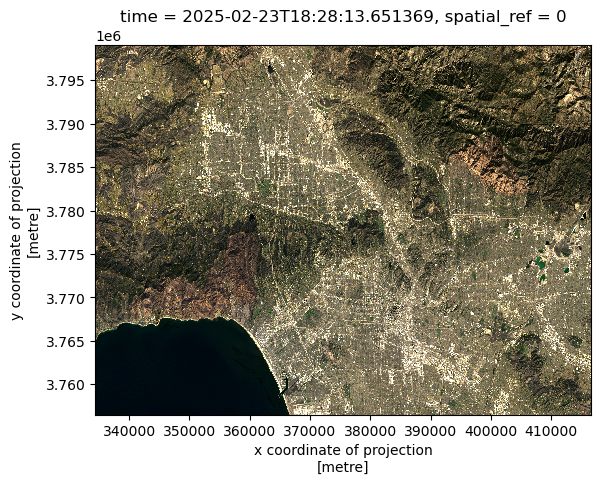

In [23]:
landsat[['red','green','blue']].to_dataarray().plot.imshow(robust=True)

In [24]:
bands = ['red','green','blue']

for band in bands:
    na_total = int(np.isnan(landsat[band]).sum())
    print(f"The {band} band has {na_total} NA values.")


The red band has 0 NA values.
The green band has 1 NA values.
The blue band has 109 NA values.


In [25]:
landsat = landsat.fillna(value=0) 

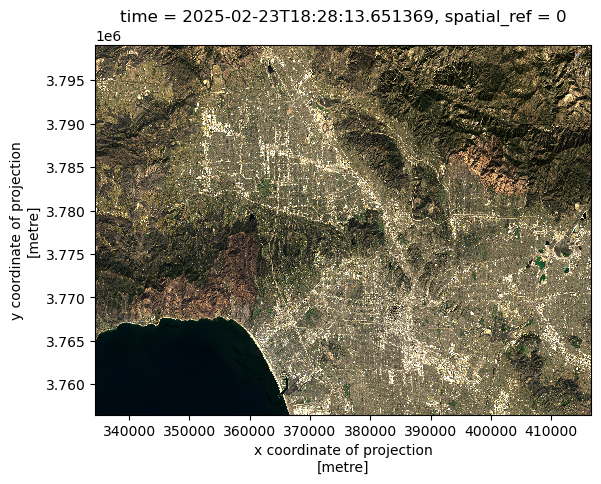

In [26]:
landsat[['red','green','blue']].to_dataarray().plot.imshow(robust=True)

In a markdown cell write a brief explanation comparing the outputs for parts (a) and (e).

# 6. False color image

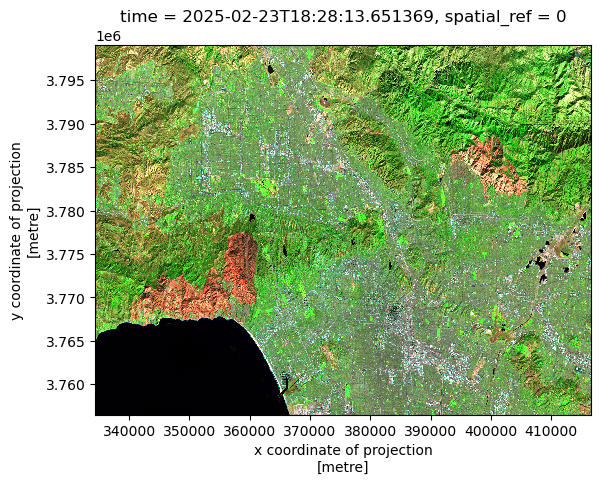

In [27]:
landsat[["swir22", "nir08", "red"]].to_dataarray().plot.imshow(robust=True)

# 7. Map

Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire perimeters. Customize it appropriately including, at least, an informative title and legend. You may also want to include text on the map to identify which fire is which.

Write a figure description for the map including a brief explanation of how false color imagery is being used.

In [29]:
eaton = eaton.to_crs(landsat.rio.crs)
palisades = palisades.to_crs(landsat.rio.crs)

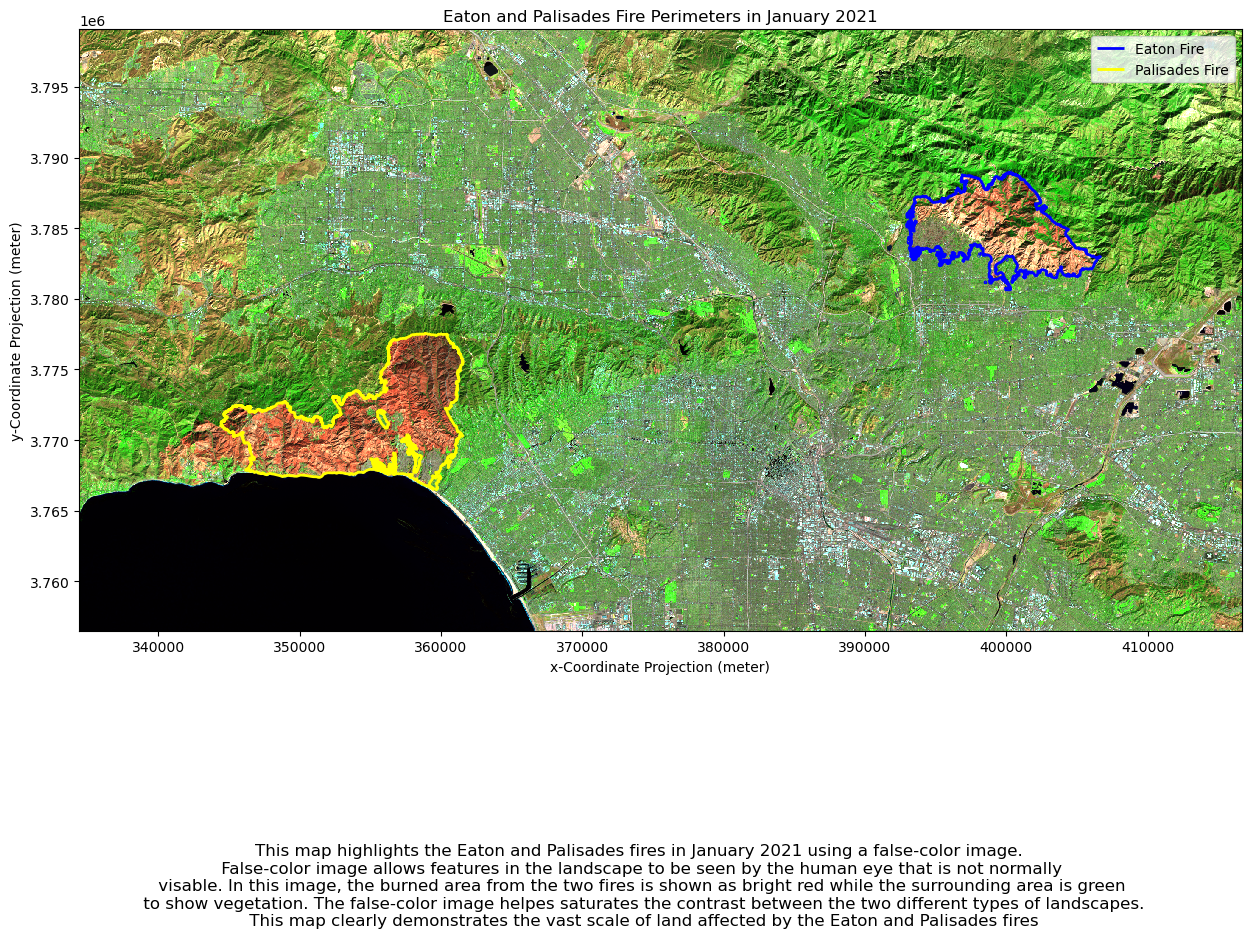

In [60]:
fires = pd.concat([eaton, palisades])

# Finding max coordinates of fire polygons to add fire names as text annotations
eaton_max = eaton.geometry.get_coordinates().max()
palisades_max = palisades.geometry.get_coordinates().max()

# Adding max coordinates to iterable list
max_x = [eaton_max.iloc[0], palisades_max.iloc[0]]
max_y = [eaton_max.iloc[1], palisades_max.iloc[1]]

# Plotting
fig, ax = plt.subplots(figsize=(15,10))

landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(ax=ax, robust=True)
eaton.boundary.plot(ax=ax, color='blue', linewidth=2, label = 'Eaton Fire')
palisades.boundary.plot(ax=ax, color='yellow', linewidth=2, label = 'Palisades Fire')

plt.xlabel('x-Coordinate Projection (meter)')
plt.ylabel('y-Coordinate Projection (meter)')
plt.title('Eaton and Palisades Fire Perimeters in January 2021')
plt.legend()

plt.figtext(0.5, -0.10, 'This map highlights the Eaton and Palisades fires in January 2021 using a false-color image. \n False-color image allows features in the landscape to be seen by the human eye that is not normally \n visable. In this image, the burned area from the two fires is shown as bright red while the surrounding area is green \n to show vegetation. The false-color image helpes saturates the contrast between the two different types of landscapes.\n This map clearly demonstrates the vast scale of land affected by the Eaton and Palisades fires',
    ha = 'center', fontsize = 12)

plt.show()